# Forecasting Hands and Objects, joined to narrations

This notebook loads the Ego4D Forecasting Hands and Objects train and validation tables and joins each verb to one narration sentence. Videos that appear in both splits are removed before any count, plot, or model. The verb chart and the three labelers use only the 37 verbs whose Ego4D head is also an AgiBot skill name. AgiBot commands are listed for hand labeling. No hand-label file is on disk, so those columns are left blank and the labelers are not scored on AgiBot.

Every count, filter, and figure comes from `src/eg04d_join.py`. The cells below only call that module.

Ego4D is read from `/Users/riaaleksanyan/data/ego4d` when that folder exists, and otherwise from `data/ego4d` in this project. AgiBot commands are read from `/Users/riaaleksanyan/data/agibot/task_info`.


## Setup

Import the join module and point it at the local annotation directory.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src" / "eg04d_join.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import eg04d_join as join

EGO4D_DIR = Path("/Users/riaaleksanyan/data/ego4d")
if not EGO4D_DIR.exists():
    EGO4D_DIR = ROOT / "data" / "ego4d"
AGIBOT_DIR = Path("/Users/riaaleksanyan/data/agibot/task_info")
DATA_DIR = EGO4D_DIR
DATA_DIR, AGIBOT_DIR

(PosixPath('/Users/riaaleksanyan/Documents/Princeton/project-424/data/ego4d'), PosixPath('/Users/riaaleksanyan/data/agibot/task_info'))

## Load the joined table

Repeated forecast rows collapse to one action. A narration is kept only when its timestamp falls inside the action window. The revised narration pass is used when a video has one. The camera-wearer tag is removed, and the verb, including the words inside a label such as `take_(pick,_grab,_get)`, is removed from the sentence.

Videos that appear in both the train file and the validation file are then removed from both splits. After that removal, no video is in both splits. Participant overlap is recomputed on the rows that remain.


In [2]:
paths = join.resolve_annotation_paths(DATA_DIR)
notes, _ = join.build_joined_table(DATA_DIR)
notes, counts, leakage = join.without_shared_videos(notes, DATA_DIR)
narrations = join.load_narrations(paths.narrations)
scoring = join.scoring_rows(notes)
notes.shape


(44392, 15)

## Descriptive statistics

These figures describe the joined table after the shared videos are removed. Joined rows still include ambiguous matches. Scoring rows are the ones a later model is allowed to see. The verb count here is every remaining Ego4D label, not only the 37 shared verbs.


In [3]:
join.descriptive_statistics(notes)

joined_rows              44392.000000
scoring_rows             26788.000000
videos                     922.000000
participants               189.000000
verbs                      112.000000
train_rows               32587.000000
val_rows                 11805.000000
median_leftover_words        4.000000
mean_leftover_words          4.694303

## Verb frequency

The chart is limited to the 37 shared verbs: an Ego4D taxonomy head that is also an AgiBot skill name. The rows are the leakage-free scoring set. Verbs outside that list are not plotted. A shared verb with no remaining rows is shown as zero.


In [4]:
shared = join.shared_verbs(DATA_DIR, AGIBOT_DIR)
join.shared_verb_frequency(scoring, shared)


verb
move       1308
hold       1306
remove      928
open        773
cut         770
turn        733
pour        484
close       445
paint       425
pull        399
throw       338
lift        324
carry       272
dip         263
wipe        259
scoop       214
press       202
push        178
fold        168
insert      133
roll        130
peel         78
shake        66
screw        66
knead        64
tie          57
iron         48
hang         44
unfold       32
water        30
stretch      27
unscrew      23
untie        16
catch         3
point         2
wave          2
clap          1

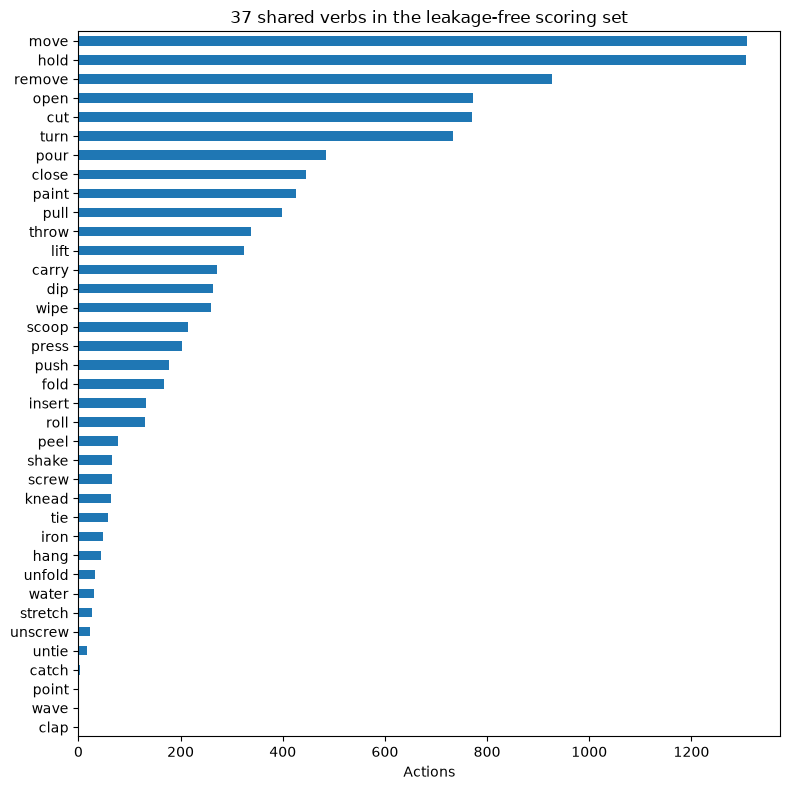

In [5]:
join.plot_shared_verbs(scoring, shared)


## Narrations per video

These counts come from the narration file, before the join. Each video contributes the revised pass when that pass exists, and the original pass otherwise.

In [6]:
per_video = join.narrations_per_video(narrations)
join.narration_video_summary(per_video)

videos                    8886.0
narration_sentences    2515187.0
median_per_video           171.0
max_per_video             5327.0

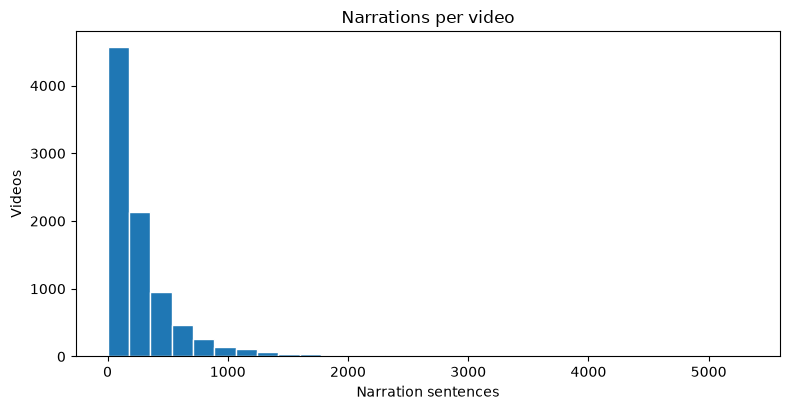

In [7]:
join.plot_narrations_per_video(per_video)

## Preprocessing

The join already removed a leading `C` or `#C` tag and deleted the labeled verb from each sentence. `verb_remains` is true when a form of that verb is still in the leftover, which means the strip missed it. Ambiguous rows, where two sentences inside the window are about equally close, stay in the table and are dropped by `scoring_rows`. These counts are on the table after the shared videos were removed.


In [8]:
join.preprocessing_summary(notes)

rows_with_narration       44392.0
ambiguous_rows            17604.0
rows_kept_for_scoring     26788.0
verb_still_in_leftover        0.0
empty_leftovers              19.0
median_leftover_words         5.0

In [9]:
join.preprocessing_examples(notes)

,split,verb,narration,leftover,verb_remains,ambiguous
0,train,"put_(place,_leave,_drop)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
1,train,"hold_(support,_grip,_grasp)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
2,train,mix,pours more water in the plastic tin.,pours more water in the plastic tin,False,False
3,train,"take_(pick,_grab,_get)",pours more water in the plastic tin.,pours more water in the plastic tin,False,False
4,train,carry,puts the cup of water on the sink.,puts the cup of water on the sink,False,True
5,train,"put_(place,_leave,_drop)",puts the cup of water on the sink.,the cup of water on the sink,False,False
6,train,"take_(pick,_grab,_get)",puts the cup of water on the sink.,puts the cup of water on the sink,False,False
7,train,"put_(place,_leave,_drop)",puts the cup of water on the sink.,the cup of water on the sink,False,False


## Preliminary results

The first line is how many videos were in both splits and were removed. Collapsed actions are counted on the videos that remain. Rows surviving the join matched one narration and were not ambiguous. Ambiguous rows are excluded from scoring. The last count is validation rows whose participant also appears on a remaining training row.


In [10]:
print(leakage.to_string())
join.counts_table(counts)


videos_in_both_files      219
videos_removed            219
train_videos_remaining    659
val_videos_remaining      263
videos_still_in_both        0


,count
collapsed actions,63654
rows surviving the join,26788
ambiguous rows dropped,17604
validation rows whose participant is also in training,5600


## AgiBot commands

Each `action_text` is one robot command, ready for the hand labels the proposal uses. Two people assign a verb independently. Where they agree, that verb is the test label. Where they disagree, both marks are kept and the count is reported.

No hand-label file is in this project or in the AgiBot folder. The label columns are therefore blank. The skill name is not used as a label, and a verb is not guessed from the words in the command. There is no AgiBot score and no AgiBot verb chart until those labels exist.


In [11]:
join.hand_label_counts(AGIBOT_DIR)


task_files                  217
command_rows            1001585
hand_label_file            none
rows_labeled_by_both          0
agreements                    0
disagreements                 0
rows_still_unlabeled    1001585

In [12]:
join.hand_label_examples(AGIBOT_DIR)


,task_id,action_text,ria_verb,naomi_verb,agreed_verb
0,327,Retrieve cucumber from the shelf.,,,
1,327,Place the held cucumber into the plastic bag in the shopping cart.,,,
2,327,Retrieve tomato from the shelf.,,,
3,327,Place the held tomato into the plastic bag in the shopping cart.,,,
4,327,Retrieve corn from the shelf.,,,
5,327,Place the held corn into the shopping cart's plastic bag.,,,
6,327,Retrieve pear from the shelf.,,,
7,327,Place the held pear into the plastic bag in the shopping cart.,,,


No AgiBot verb chart is drawn. Hand labels are not on disk, and plotting the skill field would present an automatic label as if it were the test label.


## Three verb labelers

The labelers are fit only on leakage-free Ego4D training rows whose taxonomy head is one of the 37 shared verbs. The verb has already been removed from the sentence. They are scored on the validation rows in that same list. A second score drops validation rows whose participant also appears in training.

The word-count model is TF-IDF unigrams and bigrams plus logistic regression, fit on the training leftovers. The embedding model passes each leftover through frozen all-MiniLM-L6-v2 and uses a separate logistic regression. The rule guesses a shared verb only when exactly one of those verbs is still written in the leftover. Otherwise it guesses the most common of the 37 in the training rows. Put is not in the 37, so that most common verb is the floor. AgiBot is not scored, because it has no hand labels.


In [13]:
summary, scores = join.fit_verb_labelers(notes, shared)
print(summary.to_string())
scores


shared_verbs             37
train_rows             7790
val_rows               2821
floor_verb             hold
verbs_in_validation      34


,program,rows,n,accuracy,macro_f1
0,word count,all validation rows,2821,0.193194,0.077734
1,word count,participant overlap removed,627,0.156300,0.074025
2,sentence embedding,all validation rows,2821,0.180078,0.076646
3,sentence embedding,participant overlap removed,627,0.140351,0.075835
4,rule,all validation rows,2821,0.075151,0.005282
5,rule,participant overlap removed,627,0.068581,0.005461
